# Classical ML Models — Insurance Fraud Detection

In [13]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import LinearSVC
from sklearn.calibration import CalibratedClassifierCV
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score

df = pd.read_csv("../data/carclaims.csv")
y = df["FraudFound"].map({"Yes": 1, "No": 0})
X = df.drop(columns=["PolicyNumber", "RepNumber", "Year", "FraudFound"])

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

num_cols = X_train.select_dtypes(include="number").columns.tolist()
cat_cols = X_train.select_dtypes(exclude="number").columns.tolist()

preprocessor = ColumnTransformer([
    ("num", StandardScaler(), num_cols),
    ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat_cols)
])

def evaluate(model, model_name, threshold=0.30):
    for split, X, y in [("TRAIN", X_train, y_train), ("TEST", X_test, y_test)]:
        prob = model.predict_proba(X)[:, 1]
        pred = (prob >= threshold).astype(int)
        r = classification_report(y, pred, target_names=["No Fraud", "Fraud"], output_dict=True, zero_division=0)
        print(f"{split} — Recall: {r['Fraud']['recall']:.2f} | F1: {r['Fraud']['f1-score']:.2f} | AUC: {roc_auc_score(y, prob):.4f}")
    print(confusion_matrix(y_test, (model.predict_proba(X_test)[:, 1] >= threshold).astype(int)))
    print(classification_report(y_test, (model.predict_proba(X_test)[:, 1] >= threshold).astype(int), target_names=["No Fraud", "Fraud"], zero_division=0))

print("Setup complete.")


Setup complete.


## 1. Decision Tree

In [15]:
dt_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", DecisionTreeClassifier(class_weight="balanced", random_state=42))
])

dt_model.fit(X_train, y_train)
evaluate(dt_model, "Decision Tree")


TRAIN — Recall: 1.00 | F1: 1.00 | AUC: 1.0000
TEST — Recall: 0.16 | F1: 0.15 | AUC: 0.5487
[[2727  172]
 [ 156   29]]
              precision    recall  f1-score   support

    No Fraud       0.95      0.94      0.94      2899
       Fraud       0.14      0.16      0.15       185

    accuracy                           0.89      3084
   macro avg       0.55      0.55      0.55      3084
weighted avg       0.90      0.89      0.90      3084



## 2. Random Forest

In [ ]:
rf_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(class_weight="balanced", n_estimators=100,max_depth=10,min_samples_leaf=5, random_state=42))
])

rf_model.fit(X_train, y_train)
evaluate(rf_model, "Random Forest")


 Random Forest

Metric                    TRAIN       TEST
----------------------------------------
Fraud Recall               0.98       0.97
Fraud F1                   0.23       0.22
ROC-AUC                  0.9233     0.8152

Test Confusion Matrix:
[[1655 1244]
 [   5  180]]

Test Classification Report:
              precision    recall  f1-score   support

    No Fraud       1.00      0.57      0.73      2899
       Fraud       0.13      0.97      0.22       185

    accuracy                           0.60      3084
   macro avg       0.56      0.77      0.47      3084
weighted avg       0.94      0.60      0.70      3084



## 3. SVM (LinearSVC)

In [16]:
svm_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", CalibratedClassifierCV(LinearSVC(class_weight="balanced", random_state=42, max_iter=2000)))
])

svm_model.fit(X_train, y_train)
evaluate(svm_model, "SVM (LinearSVC)")

TRAIN — Recall: 0.02 | F1: 0.04 | AUC: 0.8326
TEST — Recall: 0.01 | F1: 0.02 | AUC: 0.8048
[[2876   23]
 [ 183    2]]
              precision    recall  f1-score   support

    No Fraud       0.94      0.99      0.97      2899
       Fraud       0.08      0.01      0.02       185

    accuracy                           0.93      3084
   macro avg       0.51      0.50      0.49      3084
weighted avg       0.89      0.93      0.91      3084



Save best model 

In [18]:
import joblib
joblib.dump(rf_model, "../model/best_model_rf.pkl")
print("Model saved.")


Model saved.


Model COmparison

        Model  Fraud Recall  Fraud F1  ROC-AUC
Decision Tree          0.16      0.15     0.55
Random Forest          0.97      0.22     0.82
          SVM          0.01      0.02     0.80


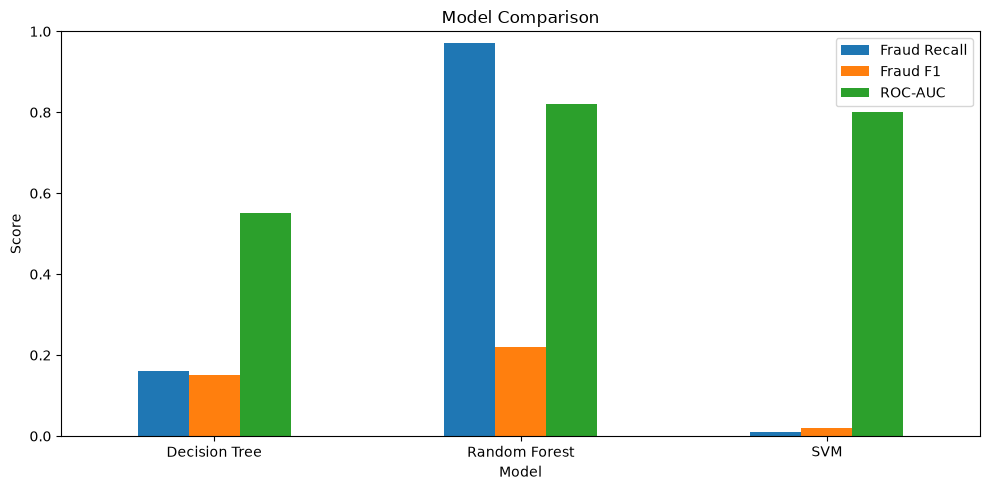

In [19]:
import pandas as pd
import matplotlib.pyplot as plt

results = pd.DataFrame({
    "Model":        ["Decision Tree", "Random Forest", "SVM"],
    "Fraud Recall": [0.16, 0.97, 0.01],
    "Fraud F1":     [0.15, 0.22, 0.02],
    "ROC-AUC":      [0.55, 0.82, 0.80]
})

print(results.to_string(index=False))

results.set_index("Model").plot(kind="bar", figsize=(10, 5), rot=0)
plt.title("Model Comparison")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.tight_layout()
plt.show()
